# Used Car Selling Price Prediction Using Machine Learning

## Project Overview

This project uses a used-car dataset to explore factors associated with vehicle selling prices and prepare the data for machine-learning analysis.

The project includes exploratory data analysis, data cleaning, missing-value treatment, duplicate removal, outlier treatment, feature engineering, categorical encoding, numerical feature scaling, and preparation of training and testing datasets.

The target variable for the project is `selling_price`.

## Dataset Description

The dataset contains information about used vehicles, including vehicle type, make, year, selling price, kilometers driven, fuel type, seller type, transmission, ownership, mileage, engine, maximum power, and number of seats.

The target variable for this project is `selling_price`. The dataset is used to explore factors associated with used-car selling prices and to prepare the data for machine-learning analysis.

In [7]:
import pandas as pd


In [8]:
df = pd.read_excel("PROJECTcardekho.xlsx")

In [9]:
df.shape

(4023, 13)

In [10]:
df.head()


,type,make,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage(km/ltr/kg),engine,max_power,seats
0,Audi,Audi A3 35 TDI Premium Plus,2017,2600000,70000,Diesel,Individual,Automatic,First Owner,20.38,1968.0,143.00,5.0
1,Audi,Audi A3 35 TDI Premium Plus,2018,3000000,20000,Diesel,Individual,Automatic,First Owner,20.38,1968.0,143.00,5.0
2,Audi,Audi A3 40 TFSI Premium,2017,1689999,8000,Petrol,Dealer,Automatic,First Owner,16.60,1798.0,177.50,5.0
3,Audi,Audi A4 1.8 TFSI,2010,730000,55000,Petrol,Individual,Automatic,Second Owner,12.30,1781.0,163.20,5.0
4,Audi,Audi A4 2.0 TDI,2014,1600000,44000,Diesel,Individual,Automatic,Second Owner,16.55,1968.0,147.51,5.0


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4023 entries, 0 to 4022
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   type                4023 non-null   object 
 1   make                4023 non-null   object 
 2   year                4023 non-null   int64  
 3   selling_price       4023 non-null   int64  
 4   km_driven           4023 non-null   int64  
 5   fuel                4023 non-null   object 
 6   seller_type         4023 non-null   object 
 7   transmission        4023 non-null   object 
 8   owner               4023 non-null   object 
 9   mileage(km/ltr/kg)  3912 non-null   float64
 10  engine              3912 non-null   float64
 11  max_power           3912 non-null   float64
 12  seats               3912 non-null   float64
dtypes: float64(4), int64(3), object(6)
memory usage: 408.7+ KB


## Data Loading and Initial Inspection

The original dataset was loaded into Python using Pandas. Initial inspection was performed before preprocessing to understand the structure of the dataset, including the number of observations, variables, data types, and missing values.

In [12]:
df.isnull().sum()

,0
type,0
make,0
year,0
selling_price,0
km_driven,0
fuel,0
seller_type,0
transmission,0
owner,0
mileage(km/ltr/kg),111


In [13]:
df.duplicated().sum()

np.int64(734)

In [14]:
df.describe()

,year,selling_price,km_driven,mileage(km/ltr/kg),engine,max_power,seats
count,4023.000000,4.023000e+03,4.023000e+03,3912.000000,3912.000000,3912.000000,3912.000000
mean,2014.102411,7.894626e+05,6.834087e+04,18.886521,1529.938650,102.077506,5.262014
std,3.670741,9.704273e+05,6.083802e+04,3.824618,486.820272,38.613746,0.788312
min,1999.000000,3.000000e+04,1.000000e+03,0.000000,799.000000,53.260000,4.000000
25%,2012.000000,3.000000e+05,3.000000e+04,16.800000,1197.000000,78.000000,5.000000
50%,2015.000000,5.000000e+05,6.000000e+04,18.900000,1461.000000,88.760000,5.000000
75%,2017.000000,7.500000e+05,9.100000e+04,21.430000,1598.000000,116.300000,5.000000
max,2020.000000,7.200000e+06,2.360457e+06,27.400000,3604.000000,282.000000,10.000000


In [15]:
df.describe(include='object')

,type,make,fuel,seller_type,transmission,owner
count,4023,4023,4023,4023,4023,4023
unique,17,1130,4,3,2,5
top,Hyundai,BMW X4 M Sport X xDrive20d,Diesel,Individual,Manual,First Owner
freq,1415,62,2186,3113,3263,2655


In [16]:
from sklearn.model_selection import train_test_split

## Train-Test Split

The dataset was divided into training and testing sets using Python's `train_test_split` function. A 70/30 split was used, with 70% of the observations assigned to the training dataset and 30% assigned to the testing dataset. The training data was used for exploratory data analysis and to fit preprocessing transformations, while the testing data was kept separate for later evaluation.

In [17]:
train_df, test_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42
)

In [18]:
train_df.shape

(2816, 13)

In [19]:
print("Original dataset:", df.shape)
print("Training dataset:", train_df.shape)
print("Testing dataset:", test_df.shape)

Original dataset: (4023, 13)
Training dataset: (2816, 13)
Testing dataset: (1207, 13)


In [20]:
train_df.head()

,type,make,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage(km/ltr/kg),engine,max_power,seats
1432,Hyundai,Hyundai Elantra SX,2012,550000,95000,Petrol,Individual,Manual,First Owner,16.30,1797.0,147.5,5.0
3846,Volkswagen,Volkswagen Polo 1.5 TDI Comfortline,2014,350000,60000,Diesel,Individual,Manual,Second Owner,20.14,1498.0,88.8,5.0
1511,Hyundai,Hyundai EON Era Plus,2014,260000,18945,Petrol,Individual,Manual,First Owner,21.10,814.0,55.2,5.0
1717,Hyundai,Hyundai Grand i10 Asta,2014,455999,32000,Petrol,Individual,Manual,First Owner,18.90,1197.0,82.0,5.0
226,Chevrolet,Chevrolet Beat LT,2016,310000,30000,Petrol,Individual,Manual,First Owner,18.60,1199.0,76.8,5.0


In [21]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2816 entries, 1432 to 3174
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   type                2816 non-null   object 
 1   make                2816 non-null   object 
 2   year                2816 non-null   int64  
 3   selling_price       2816 non-null   int64  
 4   km_driven           2816 non-null   int64  
 5   fuel                2816 non-null   object 
 6   seller_type         2816 non-null   object 
 7   transmission        2816 non-null   object 
 8   owner               2816 non-null   object 
 9   mileage(km/ltr/kg)  2748 non-null   float64
 10  engine              2748 non-null   float64
 11  max_power           2748 non-null   float64
 12  seats               2748 non-null   float64
dtypes: float64(4), int64(3), object(6)
memory usage: 308.0+ KB


In [22]:
train_df.isnull().sum()

,0
type,0
make,0
year,0
selling_price,0
km_driven,0
fuel,0
seller_type,0
transmission,0
owner,0
mileage(km/ltr/kg),68


In [23]:
train_df.duplicated().sum()

np.int64(461)

In [24]:
train_df.nunique()

,0
type,17
make,960
year,22
selling_price,415
km_driven,471
fuel,4
seller_type,3
transmission,2
owner,5
mileage(km/ltr/kg),249


## Exploratory Data Analysis

Exploratory data analysis was performed using the training dataset only. The purpose was to understand the distributions of the variables and examine relationships between vehicle characteristics and selling price before preprocessing. The analysis included numerical distributions, categorical variables, and relationships between selling price and selected vehicle characteristics.

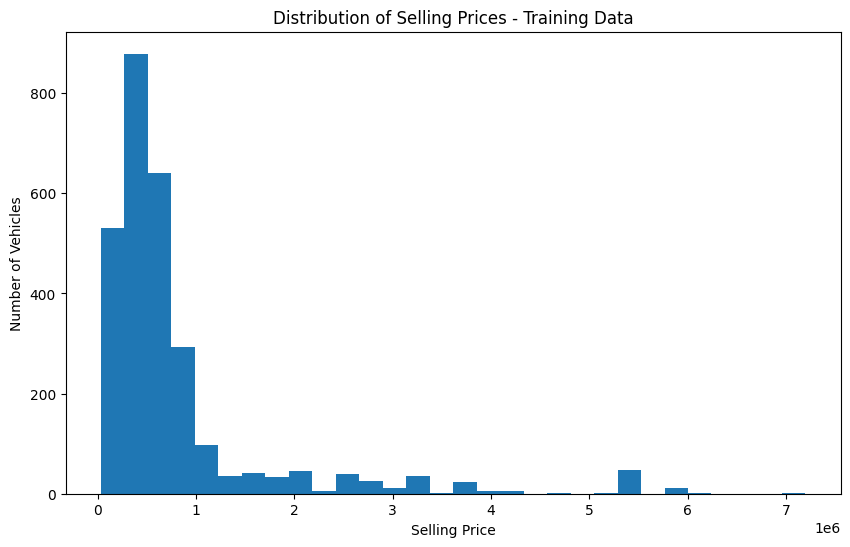

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.hist(train_df['selling_price'], bins=30)
plt.xlabel('Selling Price')
plt.ylabel('Number of Vehicles')
plt.title('Distribution of Selling Prices - Training Data')
plt.show()

### Interpretation

The selling price distribution is strong right-skewed, while most vehicles in the training dataset have lower selling prices, and a smaller number of vehicles have higher selling prices. The long right tail indicates the presence of high-priced vehicles. This distribution will be revisited during later preprocessing and machine-learning modeling.

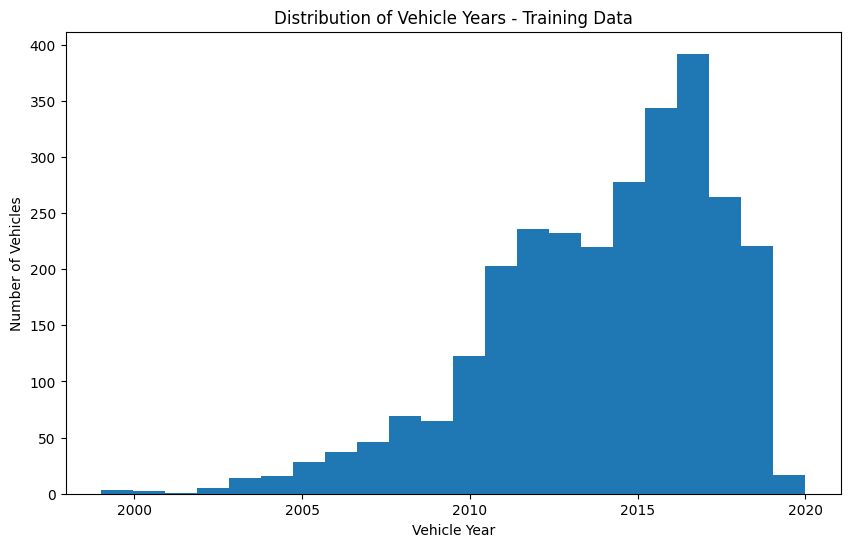

In [26]:
plt.figure(figsize=(10, 6))
plt.hist(train_df['year'], bins=22)
plt.xlabel('Vehicle Year')
plt.ylabel('Number of Vehicles')
plt.title('Distribution of Vehicle Years - Training Data')
plt.show()

### Interpretation

The vehicle-year distribution shows that the training dataset contains vehicles ranging from approximately 1999 to 2020 with most concentrated in the more recent years, particularly between 2015 and 2018. Older vehicles are less frequently represented. Vehicle year may be an important feature for predicting selling price because newer vehicles may have different market values from older vehicles.

In [27]:
train_df['fuel'].value_counts()

,count
fuel,
Diesel,1525
Petrol,1274
LPG,11
CNG,6


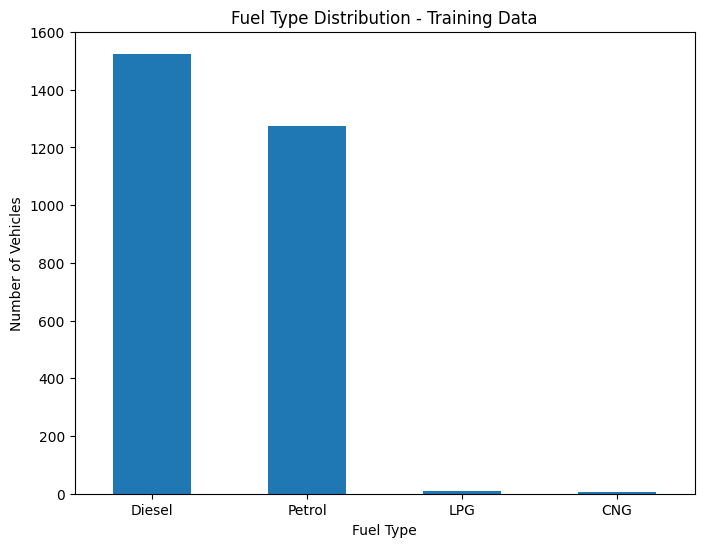

In [28]:
plt.figure(figsize=(8, 6))
train_df['fuel'].value_counts().plot(kind='bar')
plt.xlabel('Fuel Type')
plt.ylabel('Number of Vehicles')
plt.title('Fuel Type Distribution - Training Data')
plt.xticks(rotation=0)
plt.show()

### Interpretation

The fuel type distribution comes out in four categories: Diesel, Petrol, LPG, and CNG. Diesel vehicles is the largest group in the training dataset, followed by Petrol, while LPG and CNG vehicles are much less common. This shows that the fuel categories are not evenly distributed. This imbalance will be taken up during the preprocessing stage, especially when encoding categorical variables.

In [29]:
train_df['seller_type'].value_counts()

,count
seller_type,
Individual,2180
Dealer,511
Trustmark Dealer,125


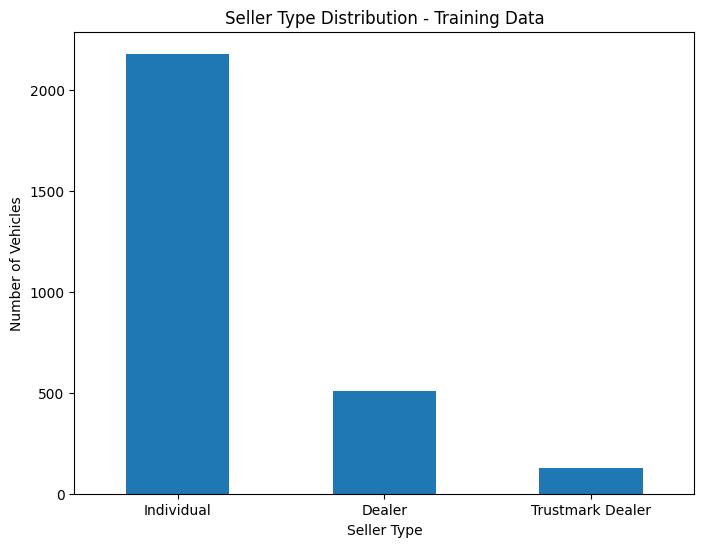

In [30]:
plt.figure(figsize=(8, 6))
train_df['seller_type'].value_counts().plot(kind='bar')
plt.xlabel('Seller Type')
plt.ylabel('Number of Vehicles')
plt.title('Seller Type Distribution - Training Data')
plt.xticks(rotation=0)
plt.show()

### Interpretation

The seller type distribution contains three categories: Individual, Dealer, and Trustmark Dealer. Individual sellers by far the largest group accounting for the majority of observations, confirming that most vehicles are sold by individual while Dealer and Trustmark Dealer represent much smaller portions of the training dataset. Therefore, the seller type variable is not evenly distributed and will need to be appropriately encoded during preprocessing.

In [31]:
train_df['transmission'].value_counts()

,count
transmission,
Manual,2273
Automatic,543


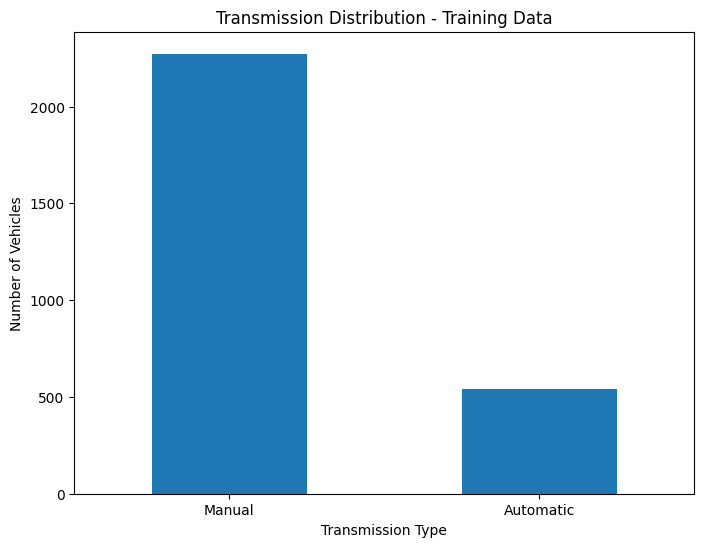

In [32]:
plt.figure(figsize=(8, 6))
train_df['transmission'].value_counts().plot(kind='bar')
plt.xlabel('Transmission Type')
plt.ylabel('Number of Vehicles')
plt.title('Transmission Distribution - Training Data')
plt.xticks(rotation=0)
plt.show()

### Interpretation

The transmission distribution shows two categories: Manual and Automatic. Manual transmission vehicles make up the majority of observations in the training dataset, while Automatic transmission vehicles represent a smaller portion. This indicates that the transmission variable is not evenly distributed and will need to be appropriately encoded during preprocessing.

In [33]:
train_df['owner'].value_counts()

,count
owner,
First Owner,1865
Second Owner,704
Third Owner,183
Fourth & Above Owner,62
Test Drive Car,2


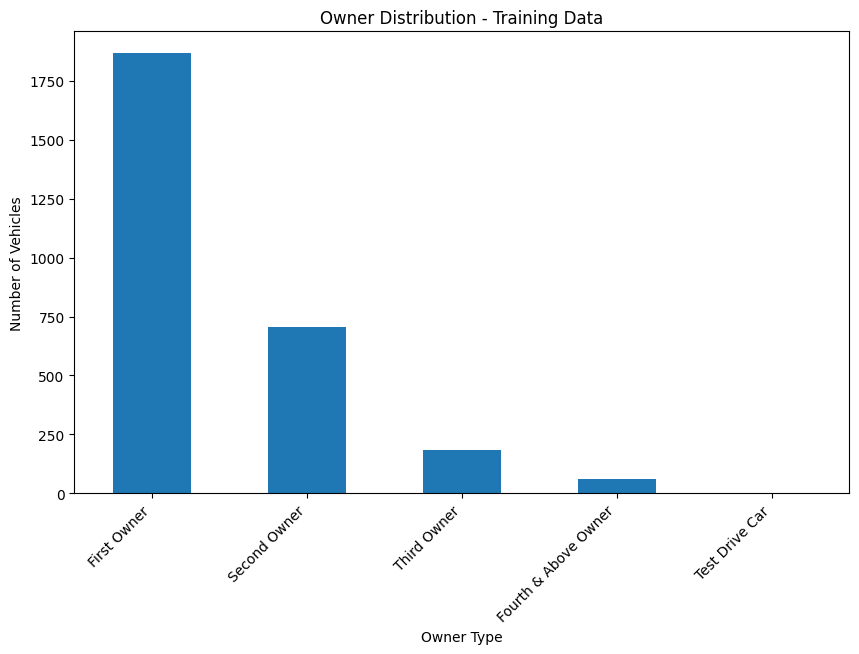

In [34]:
plt.figure(figsize=(10, 6))
train_df['owner'].value_counts().plot(kind='bar')
plt.xlabel('Owner Type')
plt.ylabel('Number of Vehicles')
plt.title('Owner Distribution - Training Data')
plt.xticks(rotation=45, ha='right')
plt.show()

### Interpretation

The owner distribution shows five categories: First Owner, Second Owner, Third Owner, Fourth & Above Owner, and Test Drive Car. First Owner vehicles represent the majority of observations, followed by Second Owner vehicles. The remaining categories contain substantially fewer observations. This indicates that the owner variable is unevenly distributed and will need to be appropriately encoded during preprocessing.

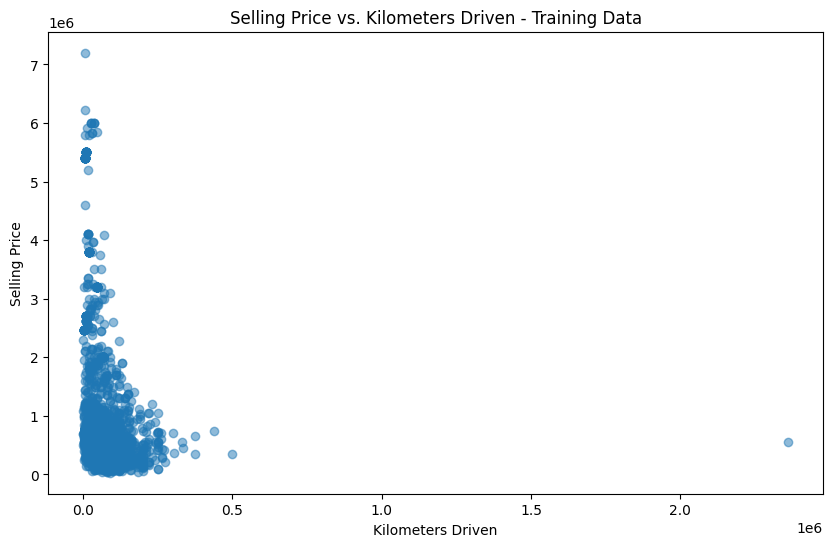

In [35]:
plt.figure(figsize=(10, 6))
plt.scatter(train_df['km_driven'], train_df['selling_price'], alpha=0.5)
plt.xlabel('Kilometers Driven')
plt.ylabel('Selling Price')
plt.title('Selling Price vs. Kilometers Driven - Training Data')
plt.show()

### Interpretation

The scatter plot shows the relationship between kilometers driven and selling price in the training data. Most vehicles have relatively low to moderate kilometer readings and selling prices as they are concentrated below roughly 500,000km. A small number of observations have unusually high kilometers driven or unusually high selling prices. These extreme observations may influence machine-learning models and should therefore be investigated during the preprocessing stage.

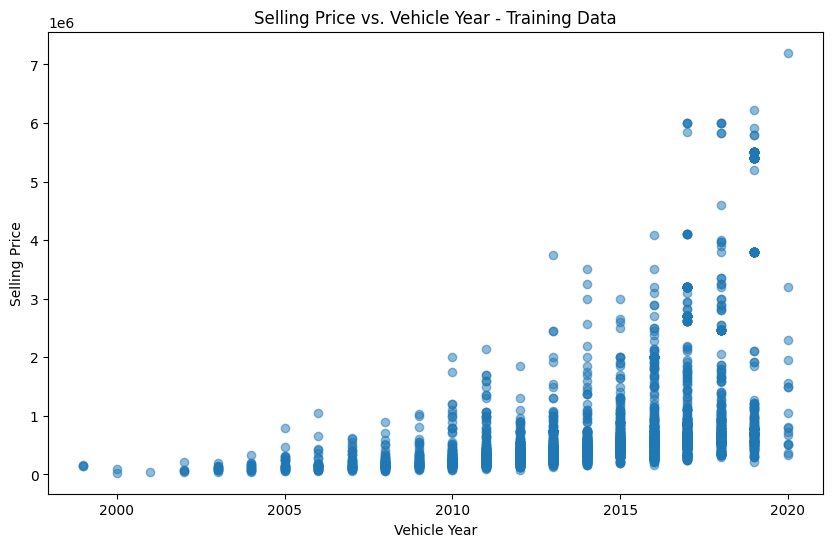

In [36]:
plt.figure(figsize=(10, 6))
plt.scatter(train_df['year'], train_df['selling_price'], alpha=0.5)
plt.xlabel('Vehicle Year')
plt.ylabel('Selling Price')
plt.title('Selling Price vs. Vehicle Year - Training Data')
plt.show()

### Interpretation

The scatter plot shows the relationship between vehicle year and selling price. Older vehicles generally have lower selling prices, while newer vehicles show a wider range of selling prices and include several higher-priced vehicles. This suggests that vehicle year may be an important feature for predicting selling price. Some unusually high selling-price observations are also visible and will be investigated during preprocessing.

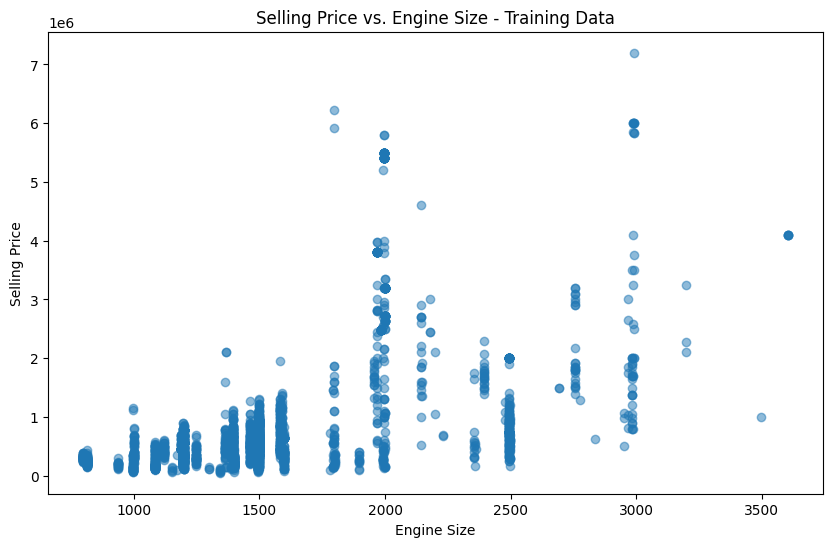

In [37]:
plt.figure(figsize=(10, 6))
plt.scatter(train_df['engine'], train_df['selling_price'], alpha=0.5)
plt.xlabel('Engine Size')
plt.ylabel('Selling Price')
plt.title('Selling Price vs. Engine Size - Training Data')
plt.show()

### Interpretation

The scatter plot shows the relationship between engine size and selling price. Vehicles with larger engines include several higher-priced observations, although selling prices vary considerably within similar engine sizes. This indicates that engine size may provide useful information for predicting selling price, but it is not the only factor affecting vehicle price. Several high-price observations will be investigated during preprocessing.

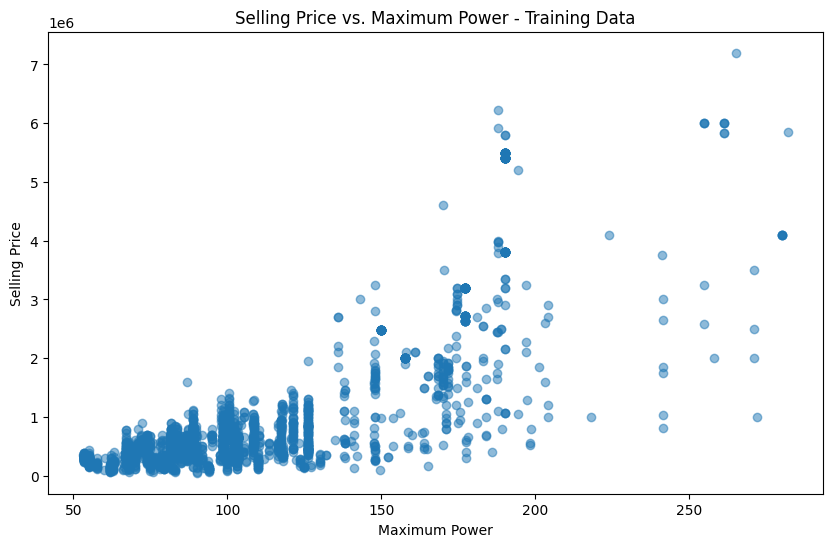

In [38]:
plt.figure(figsize=(10, 6))
plt.scatter(train_df['max_power'], train_df['selling_price'], alpha=0.5)
plt.xlabel('Maximum Power')
plt.ylabel('Selling Price')
plt.title('Selling Price vs. Maximum Power - Training Data')
plt.show()

### Interpretation

The scatter plot shows the relationship between maximum power and selling price. Vehicles with higher maximum power include more observations with higher selling prices, suggesting a positive association between the two variables. However, there is considerable variation in selling price at similar power levels. Therefore, maximum power may be a useful predictor of selling price when combined with other vehicle characteristics.

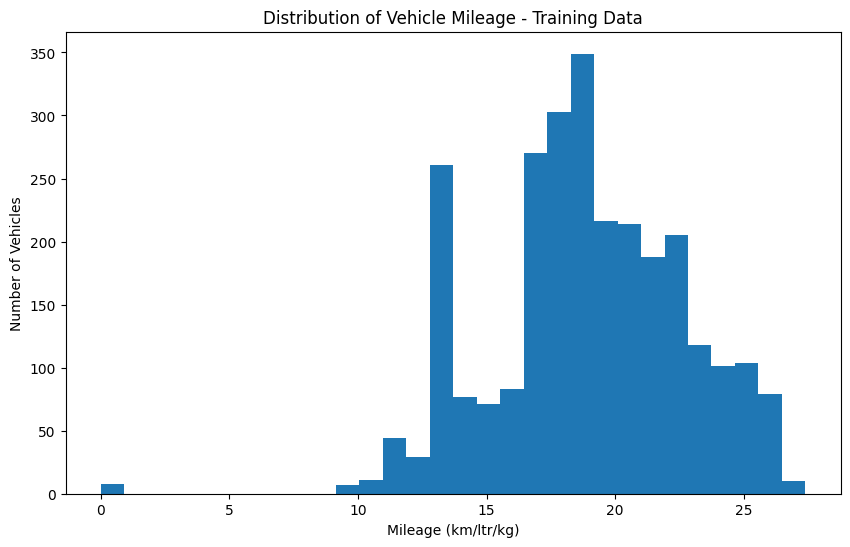

In [39]:
plt.figure(figsize=(10, 6))
plt.hist(train_df['mileage(km/ltr/kg)'].dropna(), bins=30)
plt.xlabel('Mileage (km/ltr/kg)')
plt.ylabel('Number of Vehicles')
plt.title('Distribution of Vehicle Mileage - Training Data')
plt.show()

### Interpretation

The mileage distribution shows that most vehicles in the training dataset have mileage values between approximately 15 and 25 km/ltr/kg. A small number of observations have very low mileage values, including values close to zero, which may require further investigation. The training data also contains 68 missing mileage values. These missing values and unusual observations will be addressed during the preprocessing stage.

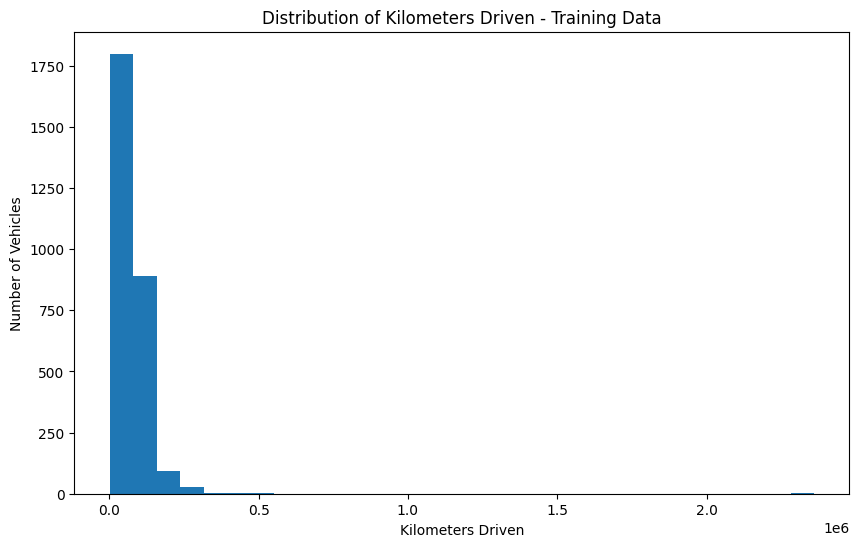

In [40]:
plt.figure(figsize=(10, 6))
plt.hist(train_df['km_driven'], bins=30)
plt.xlabel('Kilometers Driven')
plt.ylabel('Number of Vehicles')
plt.title('Distribution of Kilometers Driven - Training Data')
plt.show()

### Interpretation

The distribution of kilometers driven is strongly right-skewed. Most vehicles have relatively low to moderate kilometer readings, while a small number of vehicles have very high kilometer readings. The long right tail indicates the presence of extreme observations, including a value above two million kilometers. These observations will be investigated during preprocessing before deciding whether any treatment is appropriate.

In [41]:
train_df.nlargest(10, 'km_driven')[[
    'type',
    'make',
    'year',
    'selling_price',
    'km_driven',
    'fuel'
]]

,type,make,year,selling_price,km_driven,fuel
2147,Hyundai,Hyundai i20 Asta 1.2,2007,550000,2360457,Petrol
3545,Toyota,Toyota Innova 2.5 EV Diesel PS 7 Seater BSIII,2011,350000,500000,Diesel
3678,Toyota,Toyota Innova 2.5 VX (Diesel) 7 Seater,2013,750000,440000,Diesel
3646,Toyota,Toyota Innova 2.5 V Diesel 8-seater,2007,350000,376412,Diesel
3566,Toyota,Toyota Innova 2.5 G (Diesel) 7 Seater BS IV,2011,650000,375000,Diesel
3631,Toyota,Toyota Innova 2.5 V Diesel 7-seater,2010,450000,334000,Diesel
2427,Hyundai,Hyundai Sonata 2.4 GDi MT,2012,550000,330000,Petrol
3643,Toyota,Toyota Innova 2.5 V Diesel 8-seater,2006,370000,305000,Diesel
3552,Toyota,Toyota Innova 2.5 G (Diesel) 7 Seater,2014,700000,300000,Diesel
3780,Toyota,Toyota Qualis GS G1,2002,210000,275000,Diesel


###
The 10 vehicles with the highest kilometers driven were examined to better understand the extreme values identified in the distribution of `km_driven`. The highest observation has 2,360,457 kilometers driven, while the remaining high-mileage observations range from 275,000 to 500,000 kilometers.

The extreme observations are associated with different vehicle types, years, selling prices, and fuel types. Because these observations may represent legitimate vehicles rather than data-entry errors, they will not be removed at this stage. Further statistical analysis using the Interquartile Range (IQR) method will be performed to identify observations that fall outside the expected range.

This investigation will help determine an appropriate preprocessing strategy while avoiding the automatic removal of potentially valid observations.

In [42]:
Q1 = train_df['km_driven'].quantile(0.25)
Q3 = train_df['km_driven'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 30000.0
Q3: 93500.0
IQR: 63500.0
Lower Bound: -65250.0
Upper Bound: 188750.0


In [43]:
outliers_km = train_df[
    (train_df['km_driven'] < lower_bound) |
    (train_df['km_driven'] > upper_bound)
]

print("Number of km_driven outliers:", len(outliers_km))

Number of km_driven outliers: 81


###

The Interquartile Range (IQR) method was used to statistically investigate extreme values in the `km_driven` variable. The first quartile (Q1) is 30,000 kilometers and the third quartile (Q3) is 93,500 kilometers, resulting in an IQR of 63,500 kilometers. The calculated upper boundary is 188,750 kilometers, while the lower boundary is -65,250 kilometers.

Because kilometers driven cannot reasonably be negative, the upper boundary is the relevant threshold for identifying unusually high values. Using this method, 81 observations are identified as statistical outliers because their `km_driven` values exceed 188,750 kilometers.

These observations will not be automatically removed because an unusually high mileage value does not necessarily indicate an error. The observations will be considered during the preprocessing stage, and an appropriate treatment will be selected based on their potential impact on the machine-learning model.

In [44]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_excel("PROJECTcardekho.xlsx")

train_df, test_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42
)

print("Original dataset:", df.shape)
print("Training dataset:", train_df.shape)
print("Testing dataset:", test_df.shape)

Original dataset: (4023, 13)
Training dataset: (2816, 13)
Testing dataset: (1207, 13)


In [45]:
Q1_price = train_df['selling_price'].quantile(0.25)
Q3_price = train_df['selling_price'].quantile(0.75)

IQR_price = Q3_price - Q1_price

lower_price = Q1_price - 1.5 * IQR_price
upper_price = Q3_price + 1.5 * IQR_price

print("Q1:", Q1_price)
print("Q3:", Q3_price)
print("IQR:", IQR_price)
print("Lower Bound:", lower_price)
print("Upper Bound:", upper_price)

Q1: 300000.0
Q3: 779000.0
IQR: 479000.0
Lower Bound: -418500.0
Upper Bound: 1497500.0


In [46]:
price_outliers = train_df[
    (train_df['selling_price'] < lower_price) |
    (train_df['selling_price'] > upper_price)
]

print("Number of selling_price outliers:", len(price_outliers))

Number of selling_price outliers: 336


###

The Interquartile Range (IQR) method was used to investigate extreme values in the `selling_price` variable. The first quartile (Q1) is 300,000 and the third quartile (Q3) is 779,000, resulting in an IQR of 479,000. The calculated lower boundary is -418,500 and the upper boundary is 1,497,500.

Because selling price cannot reasonably be negative, the upper boundary is the relevant threshold for identifying unusually high selling prices. Using this method, 336 observations have selling prices above 1,497,500 and are therefore identified as statistical outliers.

These observations will not be automatically removed because a high selling price may represent a legitimate vehicle rather than a data error. The observations will be considered during preprocessing, and an appropriate treatment will be determined based on the requirements of the machine-learning problem.

In [47]:
numeric_cols = [
    'year',
    'selling_price',
    'km_driven',
    'mileage(km/ltr/kg)',
    'engine',
    'max_power',
    'seats'
]

correlation_matrix = train_df[numeric_cols].corr()

correlation_matrix

,year,selling_price,km_driven,mileage(km/ltr/kg),engine,max_power,seats
year,1.000000,0.432306,-0.458924,0.271294,-0.065382,0.166028,-0.086958
selling_price,0.432306,1.000000,-0.229581,-0.231887,0.528752,0.779005,0.047183
km_driven,-0.458924,-0.229581,1.000000,-0.091613,0.165838,-0.076732,0.230907
mileage(km/ltr/kg),0.271294,-0.231887,-0.091613,1.000000,-0.582099,-0.418335,-0.429748
engine,-0.065382,0.528752,0.165838,-0.582099,1.000000,0.768152,0.565156
max_power,0.166028,0.779005,-0.076732,-0.418335,0.768152,1.000000,0.120113
seats,-0.086958,0.047183,0.230907,-0.429748,0.565156,0.120113,1.000000


([<matplotlib.axis.XTick at 0x77fd8991d450>,
 [Text(0, 0, 'year'),
  Text(1, 0, 'selling_price'),
  Text(2, 0, 'km_driven'),
  Text(3, 0, 'mileage(km/ltr/kg)'),
  Text(4, 0, 'engine'),
  Text(5, 0, 'max_power'),
  Text(6, 0, 'seats')])

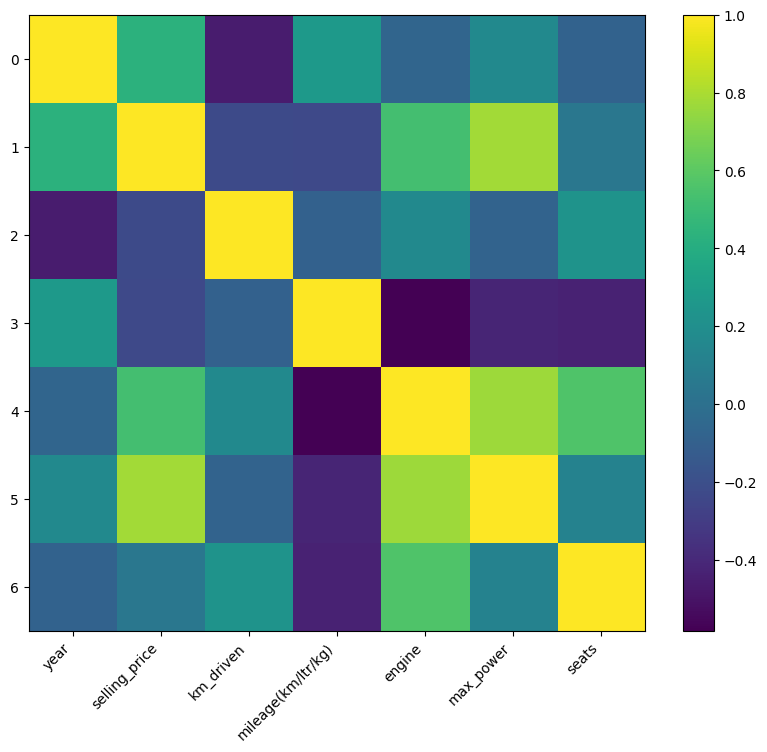

In [48]:
plt.figure(figsize=(10, 8))

plt.imshow(correlation_matrix, interpolation='none')
plt.colorbar()

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=45,
    ha='right'
)

In [49]:
import matplotlib.pyplot as plt

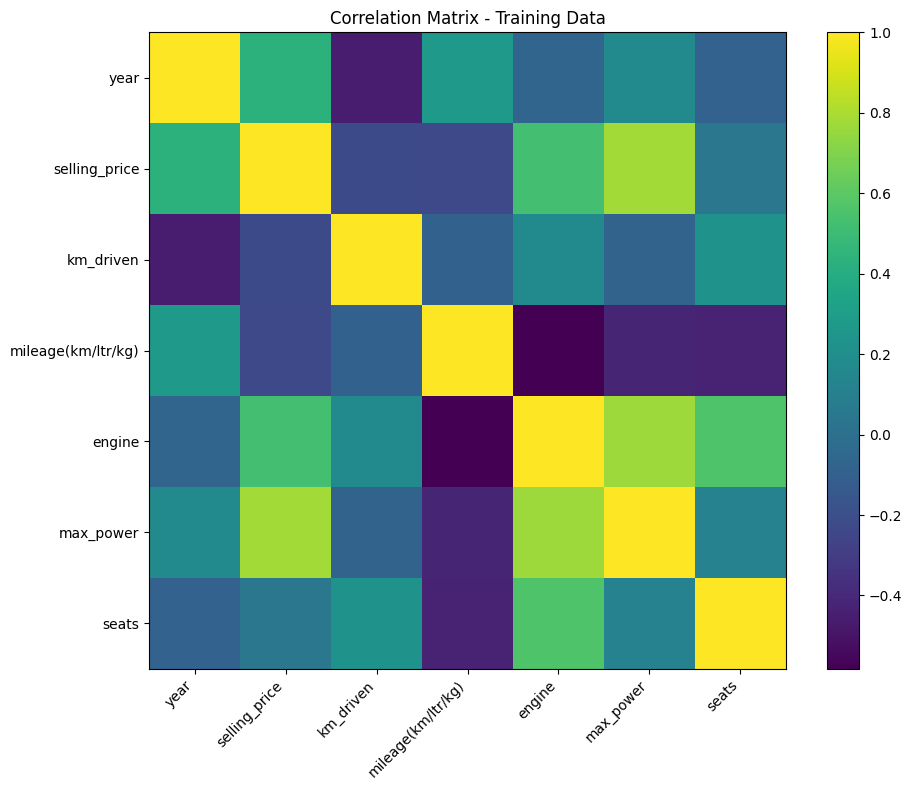

In [50]:
plt.figure(figsize=(10, 8))

plt.imshow(correlation_matrix, interpolation='none')
plt.colorbar()

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=45,
    ha='right'
)

plt.yticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns
)

plt.title('Correlation Matrix - Training Data')
plt.tight_layout()
plt.show()

###

The correlation matrix was used to examine linear relationships among the numerical variables in the training dataset. The strongest positive correlation with selling price is observed for maximum power (0.779), followed by engine size (0.529) and vehicle year (0.432). Kilometers driven (-0.230) and mileage (-0.232) show weaker negative relationships with selling price, while seats (0.047) has very little linear relationship with selling price.

The correlation between engine size and maximum power is also relatively strong (0.768), indicating that these two variables contain related information. Overall, the correlation analysis suggests that several vehicle characteristics may be useful for predicting selling price, although correlation alone does not establish causation.

## Data Cleaning and Preprocessing

The training dataset was cleaned and prepared for machine-learning analysis. The preprocessing steps included removing duplicate records, handling missing values, identifying and treating extreme values, engineering a vehicle-age feature, encoding categorical variables, and scaling numerical features. All preprocessing decisions were based on the training data to prevent information from the testing data from influencing the training process

In [51]:
train_clean = train_df.drop_duplicates().copy()

In [52]:
print("Before removing duplicates:", train_df.shape)
print("After removing duplicates:", train_clean.shape)

Before removing duplicates: (2816, 13)
After removing duplicates: (2355, 13)


In [53]:
print("Remaining duplicate rows:", train_clean.duplicated().sum())

Remaining duplicate rows: 0


###

During the exploratory data analysis, 461 duplicate records were identified in the training dataset. Duplicate records were removed using the pandas `drop_duplicates()` function. The training dataset decreased from 2,816 rows to 2,355 rows while retaining all 13 variables.


In [54]:
train_clean.isnull().sum()

,0
type,0
make,0
year,0
selling_price,0
km_driven,0
fuel,0
seller_type,0
transmission,0
owner,0
mileage(km/ltr/kg),66


In [55]:
print("Total missing values:", train_clean.isnull().sum().sum())

Total missing values: 264


After duplicate records were removed, the missing-value check was repeated. The cleaned training dataset contains 66 missing values in each of the mileage, engine, max_power, and seats variables, for a total of 264 missing values. The reduction from 68 to 66 missing values in each variable occurred because two duplicate records containing missing values were removed during the duplicate-removal process.

In [56]:
train_clean[
    ['mileage(km/ltr/kg)', 'engine', 'max_power', 'seats']
].median()

,0
mileage(km/ltr/kg),19.00
engine,1399.00
max_power,88.73
seats,5.00


## Missing-Value Treatment

Missing values were identified in four numerical variables: `mileage(km/ltr/kg)`, `engine`, `max_power`, and `seats`. The missing values were replaced using the median value calculated from the training dataset. Median imputation was used because it provides a representative value while reducing the influence of extreme observations. After imputation, a validation check confirmed that the training dataset contained no remaining missing values.

In [57]:
train_clean['mileage(km/ltr/kg)'] = train_clean['mileage(km/ltr/kg)'].fillna(19.00)

train_clean['engine'] = train_clean['engine'].fillna(1399.00)

train_clean['max_power'] = train_clean['max_power'].fillna(88.73)

train_clean['seats'] = train_clean['seats'].fillna(5.00)

In [58]:
train_clean.isnull().sum()

,0
type,0
make,0
year,0
selling_price,0
km_driven,0
fuel,0
seller_type,0
transmission,0
owner,0
mileage(km/ltr/kg),0


In [59]:
print("Total missing values:", train_clean.isnull().sum().sum())


Total missing values: 0


The missing values identified during EDA were treated using median imputation. The median values were calculated from the cleaned training dataset and used to replace missing observations in mileage, engine, max_power, and seats. Median imputation was selected because these numerical variables contain skewed distributions and extreme observations, making the median less sensitive to unusually large or small values than the mean.

After imputation, a verification check confirmed that the cleaned training dataset contains zero missing values.

## Outlier Treatment

The IQR method was used to identify extreme values in the numerical variables. For `km_driven`, the analysis identified an upper IQR boundary of 188,750 kilometers. Rather than removing observations with unusually high kilometer readings, the values were capped at the upper boundary. This approach preserves the observations while reducing the influence of extreme values on the machine-learning analysis.

The maximum `km_driven` value decreased from 2,360,457 kilometers to 188,750 kilometers after treatment.

In [60]:
train_preprocessed = train_clean.copy()

In [61]:
print("Maximum km_driven before treatment:",
      train_preprocessed['km_driven'].max())

Maximum km_driven before treatment: 2360457


In [62]:
upper_km = 188750

train_preprocessed['km_driven'] = train_preprocessed['km_driven'].clip(
    upper=upper_km
)

In [63]:
print("Maximum km_driven after treatment:",
      train_preprocessed['km_driven'].max())

Maximum km_driven after treatment: 188750


Before treatment:  2,360,457 km
After treatment:     188,750 km

The IQR analysis identified 81 statistical outliers in the km_driven variable, with an upper boundary of 188,750 kilometers. Rather than removing these observations, the extreme values were capped at the upper IQR boundary. This approach preserves the observations and the size of the training dataset while reducing the influence of unusually high kilometer readings on the machine-learning model.

The maximum km_driven value decreased from 2,360,457 to 188,750 after capping.

In [64]:
train_preprocessed.dtypes

,0
type,object
make,object
year,int64
selling_price,int64
km_driven,int64
fuel,object
seller_type,object
transmission,object
owner,object
mileage(km/ltr/kg),float64


In [65]:
train_preprocessed['make'].value_counts().head(20)

,count
make,
Hyundai EON Era Plus,32
Renault KWID RXT,24
Hyundai i10 Sportz,20
Hyundai Verna 1.6 SX,20
Ford Figo Diesel Titanium,19
Hyundai EON Magna Plus,19
Hyundai Verna 1.6 SX CRDi (O),19
Hyundai i10 Magna,18
Hyundai Grand i10 Sportz,18


In [66]:
print("Number of unique make categories:",
      train_preprocessed['make'].nunique())

Number of unique make categories: 960


In [67]:
categorical_cols = [
    'type',
    'make',
    'fuel',
    'seller_type',
    'transmission',
    'owner'
]

categorical_cols

['type', 'make', 'fuel', 'seller_type', 'transmission', 'owner']

## Categorical Encoding – One-Hot Encoding

Categorical variables were converted into numerical features using one-hot encoding. The categorical variables included `type`, `make`, `fuel`, `seller_type`, `transmission`, and `owner`.

The `OneHotEncoder` was configured with `handle_unknown='ignore'` so that categories appearing in the testing dataset but not present in the training dataset could be handled without causing an error. The `drop='first'` option was used to reduce redundant encoded features.

In [68]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(
    handle_unknown='ignore',
    drop='first',
    sparse_output=False
)

In [69]:
encoded_array = encoder.fit_transform(
    train_preprocessed[categorical_cols]
)

In [70]:
print("Original categorical columns:", len(categorical_cols))
print("Encoded columns:", encoded_array.shape[1])

Original categorical columns: 6
Encoded columns: 985


In [71]:
encoded_feature_names = encoder.get_feature_names_out(categorical_cols)

print("Number of feature names:", len(encoded_feature_names))

Number of feature names: 985


In [72]:
numerical_cols = [
    'year',
    'km_driven',
    'mileage(km/ltr/kg)',
    'engine',
    'max_power',
    'seats'
]

X_numeric = train_preprocessed[numerical_cols].copy()

In [73]:
X_encoded = pd.DataFrame(
    encoded_array,
    columns=encoded_feature_names,
    index=train_preprocessed.index
)

In [74]:
X_train = pd.concat(
    [X_numeric, X_encoded],
    axis=1
)

In [75]:
y_train = train_preprocessed['selling_price'].copy()

In [76]:
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

X_train shape: (2355, 991)
y_train shape: (2355,)


Feature Construction:
The categorical variables were converted into numerical features using one-hot encoding, producing 985 encoded features. These were combined with six numerical predictor variables: year, km_driven, mileage, engine, max_power, and seats. The selling_price variable was retained separately as the target variable. The resulting training feature matrix contains 2,355 observations and 991 predictor variables.

In [77]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

In [78]:
X_numeric_scaled = scaler.fit_transform(X_numeric)

In [79]:
X_numeric_scaled = pd.DataFrame(
    X_numeric_scaled,
    columns=numerical_cols,
    index=X_numeric.index
)

In [80]:
X_numeric_scaled.describe()

,year,km_driven,mileage(km/ltr/kg),engine,max_power,seats
count,2.355000e+03,2.355000e+03,2.355000e+03,2.355000e+03,2.355000e+03,2.355000e+03
mean,-2.180506e-14,-6.072048e-17,8.749783e-17,-2.428819e-16,4.948153e-16,8.297208e-17
std,1.000212e+00,1.000212e+00,1.000212e+00,1.000212e+00,1.000212e+00,1.000212e+00
min,-4.078181e+00,-1.605477e+00,-5.065988e+00,-1.490289e+00,-1.288968e+00,-1.574426e+00
25%,-4.844468e-01,-7.895763e-01,-5.462862e-01,-6.282833e-01,-6.470405e-01,-3.331226e-01
50%,6.843531e-02,-8.699501e-02,-1.455652e-02,-1.907828e-01,-2.416285e-01,-3.331226e-01
75%,8.977585e-01,6.382501e-01,7.032785e-01,2.055667e-01,2.609289e-01,-3.331226e-01
max,1.727082e+00,2.649672e+00,2.218708e+00,4.584903e+00,5.465144e+00,5.873394e+00


Numerical Feature Scaling:
The six numerical predictor variables were standardized using StandardScaler. The scaling was fitted to the training data after missing values and extreme km_driven values had been addressed. The resulting variables have means approximately equal to zero and standard deviations approximately equal to one. Standardization places the numerical predictors on comparable scales while retaining all 2,355 training observations.

In [81]:
X_train_final = pd.concat(
    [X_numeric_scaled, X_encoded],
    axis=1
)

In [82]:
print("Final training feature shape:", X_train_final.shape)
print("Target shape:", y_train.shape)

Final training feature shape: (2355, 991)
Target shape: (2355,)


In [83]:
print("Missing values in final features:",
      X_train_final.isnull().sum().sum())

print("Duplicate rows in final features:",
      X_train_final.duplicated().sum())

Missing values in final features: 0
Duplicate rows in final features: 46


Final Training Feature Set

The scaled numerical variables and one-hot encoded categorical variables were combined to create the final training feature matrix. The resulting dataset contains 2,355 observations and 991 predictor features, while the selling_price variable remains separate as the target variable.

A final missing-value check confirmed that there are zero missing values in the feature matrix. Although 46 duplicate rows were detected after transformation, these were not removed because feature transformation can cause different original observations to have identical numerical representations. The original duplicate records had already been removed during the data-cleaning stage.


In [84]:
test_clean = test_df.copy()

In [85]:
test_clean = test_clean.drop_duplicates().copy()

In [86]:
print("Original testing dataset:", test_df.shape)
print("After removing duplicates:", test_clean.shape)

Original testing dataset: (1207, 13)
After removing duplicates: (1080, 13)


Testing Data Duplicate Removal

The testing dataset was checked for duplicate records before applying the preprocessing transformations. The original testing dataset contained 1,207 observations. After removing duplicate records, 1,080 observations remained, representing a reduction of 127 duplicate records. The testing data was then prepared using the preprocessing rules established from the training data.

In [87]:
test_clean.isnull().sum()

,0
type,0
make,0
year,0
selling_price,0
km_driven,0
fuel,0
seller_type,0
transmission,0
owner,0
mileage(km/ltr/kg),41


In [88]:
print("Total missing values in testing data:",
      test_clean.isnull().sum().sum())

Total missing values in testing data: 164


In [89]:
test_clean['mileage(km/ltr/kg)'] = test_clean['mileage(km/ltr/kg)'].fillna(19.00)

test_clean['engine'] = test_clean['engine'].fillna(1399.00)

test_clean['max_power'] = test_clean['max_power'].fillna(88.73)

test_clean['seats'] = test_clean['seats'].fillna(5.00)

In [90]:
print("Total missing values in testing data:",
      test_clean.isnull().sum().sum())

Total missing values in testing data: 0


In [91]:
test_clean['km_driven'] = test_clean['km_driven'].clip(upper=188750)

In [92]:
print("Maximum km_driven in testing data after treatment:",
      test_clean['km_driven'].max())

Maximum km_driven in testing data after treatment: 188750


Testing Data Preprocessing

The testing dataset was prepared using the preprocessing rules established from the training dataset. Duplicate records were removed, and missing numerical values were replaced using the training-data median values. The same upper cap of 188,750 kilometers was applied to km_driven. After preprocessing, the testing dataset contained no missing values, and the maximum km_driven value was 188,750.

In [93]:
test_encoded_array = encoder.transform(
    test_clean[categorical_cols]
)

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


In [94]:
test_encoded = pd.DataFrame(
    test_encoded_array,
    columns=encoded_feature_names,
    index=test_clean.index
)

In [95]:
X_test_numeric = test_clean[numerical_cols].copy()

In [96]:
X_test_numeric_scaled = scaler.transform(X_test_numeric)

In [97]:
X_test_numeric_scaled = pd.DataFrame(
    X_test_numeric_scaled,
    columns=numerical_cols,
    index=X_test_numeric.index
)

In [98]:
X_test_final = pd.concat(
    [X_test_numeric_scaled, test_encoded],
    axis=1
)

In [99]:
y_test = test_clean['selling_price'].copy()

In [100]:
print("Final testing feature shape:", X_test_final.shape)
print("Testing target shape:", y_test.shape)

Final testing feature shape: (1080, 991)
Testing target shape: (1080,)


In [101]:
print("Missing values in final test features:",
      X_test_final.isnull().sum().sum())

Missing values in final test features: 0


Final Testing Feature Set

The testing data was transformed using the preprocessing rules learned from the training data. The categorical variables were encoded using the previously fitted OneHotEncoder, while the numerical variables were scaled using the previously fitted StandardScaler. The final testing feature matrix contains 1,080 observations and 991 predictor features, matching the feature structure of the training dataset. A final check confirmed that there are no missing values in the testing feature matrix.

In [102]:
train_preprocessed = train_clean.copy()

print("Training data shape:", train_preprocessed.shape)

Training data shape: (2355, 13)


In [103]:
reference_year = train_preprocessed['year'].max()

print("Reference year:", reference_year)

Reference year: 2020


In [104]:
train_preprocessed['vehicle_age'] = reference_year - train_preprocessed['year']

test_clean['vehicle_age'] = reference_year - test_clean['year']

In [105]:
print("Training data:")
print(train_preprocessed[['year', 'vehicle_age']].head())

print("\nTesting data:")
print(test_clean[['year', 'vehicle_age']].head())

Training data:
      year  vehicle_age
1432  2012            8
3846  2014            6
1511  2014            6
1717  2014            6
226   2016            4

Testing data:
      year  vehicle_age
1718  2016            4
1204  2016            4
2722  2017            3
1937  2011            9
1226  2017            3


## Feature Engineering - Vehicle Age

A new feature, vehicle_age, was created from the existing year variable. The reference year was set to 2020, which is the latest vehicle year in the training dataset. Vehicle age was calculated as 2020 minus the vehicle year. This transformation provides an interpretable measure of vehicle age that can be used as a predictor of used-car selling price. The same reference year and calculation were applied to both the training and testing datasets.

In [106]:
numerical_features = [
    'year',
    'km_driven',
    'mileage(km/ltr/kg)',
    'engine',
    'max_power',
    'seats',
    'vehicle_age'
]

print("Numerical features:", numerical_features)
print("Number of numerical features:", len(numerical_features))

Numerical features: ['year', 'km_driven', 'mileage(km/ltr/kg)', 'engine', 'max_power', 'seats', 'vehicle_age']
Number of numerical features: 7


In [107]:
X_train_numeric = train_preprocessed[numerical_features].copy()

In [108]:
X_train_numeric.head()

,year,km_driven,mileage(km/ltr/kg),engine,max_power,seats,vehicle_age
1432,2012,95000,16.30,1797.0,147.5,5.0,8
3846,2014,60000,20.14,1498.0,88.8,5.0,6
1511,2014,18945,21.10,814.0,55.2,5.0,6
1717,2014,32000,18.90,1197.0,82.0,5.0,6
226,2016,30000,18.60,1199.0,76.8,5.0,4


## Numerical Feature Scaling – Standardization

The numerical features were standardized using `StandardScaler`. The scaler was fitted using the training data and then used to transform the numerical features. Standardization places the numerical variables on a comparable scale by centering the values around zero and scaling them according to their standard deviation.

The same fitted scaler was later applied to the testing data to ensure that the testing features were transformed using the same scaling parameters as the training data.

In [109]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

In [111]:
X_train_numeric_scaled = scaler.fit_transform(X_train_numeric)

In [112]:
X_train_numeric_scaled = pd.DataFrame(
    X_train_numeric_scaled,
    columns=numerical_features,
    index=X_train_numeric.index
)

In [113]:
X_train_numeric_scaled.describe()

,year,km_driven,mileage(km/ltr/kg),engine,max_power,seats,vehicle_age
count,2.355000e+03,2.355000e+03,2.355000e+03,2.355000e+03,2.355000e+03,2.355000e+03,2.355000e+03
mean,-2.180506e-14,3.318883e-17,8.749783e-17,-2.428819e-16,4.948153e-16,8.297208e-17,-3.318883e-17
std,1.000212e+00,1.000212e+00,1.000212e+00,1.000212e+00,1.000212e+00,1.000212e+00,1.000212e+00
min,-4.078181e+00,-1.069407e+00,-5.065988e+00,-1.490289e+00,-1.288968e+00,-1.574426e+00,-1.727082e+00
25%,-4.844468e-01,-5.444436e-01,-5.462862e-01,-6.282833e-01,-6.470405e-01,-3.331226e-01,-8.977585e-01
50%,6.843531e-02,-9.239168e-02,-1.455652e-02,-1.907828e-01,-2.416285e-01,-3.331226e-01,-6.843531e-02
75%,8.977585e-01,3.742426e-01,7.032785e-01,2.055667e-01,2.609289e-01,-3.331226e-01,4.844468e-01
max,1.727082e+00,3.333695e+01,2.218708e+00,4.584903e+00,5.465144e+00,5.873394e+00,4.078181e+00


## Final Machine-Learning Feature Set

The standardized numerical features and one-hot encoded categorical features were combined to create the final machine-learning feature set. The target variable, `selling_price`, was kept separate from the predictor features.

The final training and testing feature matrices were prepared using the same feature structure so that they can be used consistently in subsequent machine-learning modeling.

In [114]:
X_train_final = pd.concat(
    [X_train_numeric_scaled, X_encoded],
    axis=1
)

In [115]:
print("Final training feature shape:", X_train_final.shape)

Final training feature shape: (2355, 992)


In [116]:
X_test_numeric = test_clean[numerical_features].copy()

In [117]:
X_test_numeric_scaled = scaler.transform(X_test_numeric)

In [118]:
X_test_numeric_scaled = pd.DataFrame(
    X_test_numeric_scaled,
    columns=numerical_features,
    index=X_test_numeric.index
)

In [119]:
test_encoded_array = encoder.transform(
    test_clean[categorical_cols]
)

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


In [120]:
test_encoded = pd.DataFrame(
    test_encoded_array,
    columns=encoded_feature_names,
    index=test_clean.index
)

In [121]:
X_test_final = pd.concat(
    [X_test_numeric_scaled, test_encoded],
    axis=1
)

In [122]:
print("Final testing feature shape:", X_test_final.shape)

Final testing feature shape: (1080, 992)


In [123]:
print("Training features - missing values:",
      X_train_final.isnull().sum().sum())

print("Testing features - missing values:",
      X_test_final.isnull().sum().sum())

print("Training features - duplicate rows:",
      X_train_final.duplicated().sum())

print("Testing features - duplicate rows:",
      X_test_final.duplicated().sum())

Training features - missing values: 0
Testing features - missing values: 0
Training features - duplicate rows: 46
Testing features - duplicate rows: 9


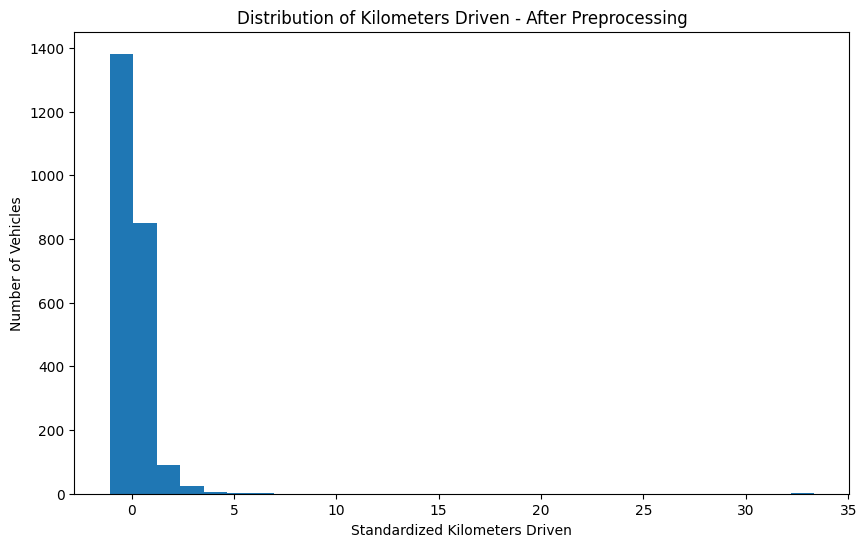

In [124]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.hist(X_train_numeric_scaled['km_driven'], bins=30)

plt.xlabel('Standardized Kilometers Driven')
plt.ylabel('Number of Vehicles')
plt.title('Distribution of Kilometers Driven - After Preprocessing')

plt.show()

After-Preprocessing Distribution - Kilometers Driven

After preprocessing, the km_driven variable was capped at the calculated upper IQR boundary of 188,750 kilometers and then standardized using StandardScaler. The resulting distribution is centered around zero, with the values placed on a common numerical scale. The preprocessing reduces the influence of extreme kilometer readings while preserving the observations in the dataset.

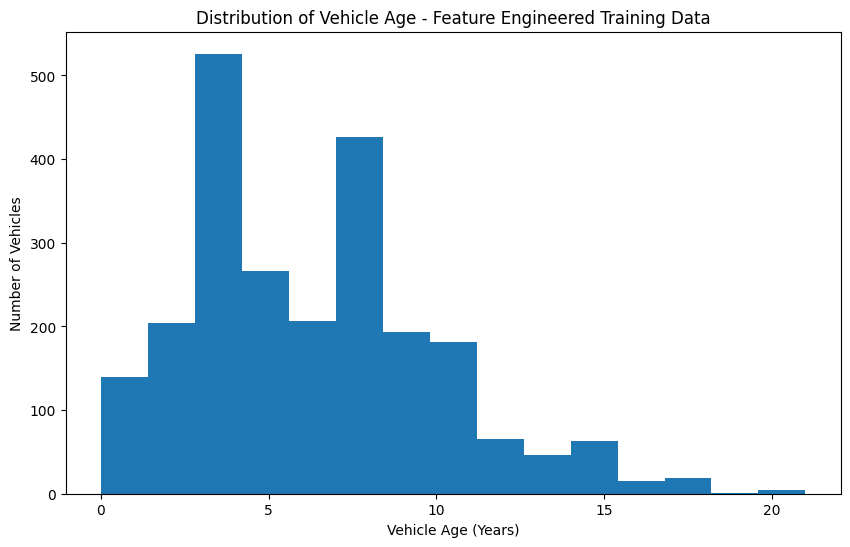

In [125]:
plt.figure(figsize=(10, 6))

plt.hist(train_preprocessed['vehicle_age'], bins=15)

plt.xlabel('Vehicle Age (Years)')
plt.ylabel('Number of Vehicles')
plt.title('Distribution of Vehicle Age - Feature Engineered Training Data')

plt.show()

Vehicle Age Distribution

The vehicle_age feature was created from the vehicle year using 2020 as the reference year. The distribution shows that most vehicles in the training dataset are relatively newer vehicles, while the number of vehicles decreases as vehicle age increases. This engineered feature provides a more direct measure of vehicle age that can be used to help predict selling price.

In [126]:
print("Final clean training dataset shape:", train_preprocessed.shape)

print("\nMissing values:")
print(train_preprocessed.isnull().sum().sum())

print("\nDuplicate rows:")
print(train_preprocessed.duplicated().sum())

print("\nColumns:")
print(train_preprocessed.columns.tolist())

Final clean training dataset shape: (2355, 14)

Missing values:
0

Duplicate rows:
0

Columns:
['type', 'make', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner', 'mileage(km/ltr/kg)', 'engine', 'max_power', 'seats', 'vehicle_age']


In [127]:
train_preprocessed.to_csv(
    'final_clean_training_dataset.csv',
    index=False
)

print("Final clean training dataset saved successfully.")

Final clean training dataset saved successfully.


In [128]:
import os

print(os.path.getsize('final_clean_training_dataset.csv'), "bytes")

271818 bytes


In [129]:
X_train_final.to_csv(
    'final_ml_training_features.csv',
    index=False
)

print("Final ML training features saved successfully.")
print("Shape:", X_train_final.shape)

Final ML training features saved successfully.
Shape: (2355, 992)


In [130]:
X_test_final.to_csv(
    'final_ml_testing_features.csv',
    index=False
)

print("Final ML testing features saved successfully.")
print("Shape:", X_test_final.shape)

Final ML testing features saved successfully.
Shape: (1080, 992)


In [131]:
test_clean.to_csv(
    'final_clean_testing_dataset.csv',
    index=False
)


In [132]:
print("Final clean testing dataset saved successfully.")
print("Shape:", test_clean.shape)

Final clean testing dataset saved successfully.
Shape: (1080, 14)


## Class Balancing

Class balancing was not applied because this project treats selling_price as a continuous numerical target for a regression problem rather than as categorical classes for a classification problem. Therefore, there are no discrete target classes that require balancing.

## Final Preprocessing Validation

The final validation confirmed that the training and testing datasets were successfully cleaned and preprocessed. The clean training dataset contains 2,355 observations and 14 columns, while the clean testing dataset contains 1,080 observations and 14 columns. Both datasets contain zero missing values and zero duplicate rows.

After categorical encoding and numerical feature scaling, the final machine-learning feature matrices contain 992 predictor features. The training feature matrix contains 2,355 observations, and the testing feature matrix contains 1,080 observations. A final check confirmed that there are no missing values in either feature matrix.

In [135]:
print("Training clean dataset shape:", train_preprocessed.shape)
print("Testing clean dataset shape:", test_clean.shape)

print("Training missing values:",
      train_preprocessed.isnull().sum().sum())

print("Testing missing values:",
      test_clean.isnull().sum().sum())

print("Training duplicate rows:",
      train_preprocessed.duplicated().sum())

print("Testing duplicate rows:",
      test_clean.duplicated().sum())

print("Final training feature shape:",
      X_train_final.shape)

print("Final testing feature shape:",
      X_test_final.shape)

print("Training feature missing values:",
      X_train_final.isnull().sum().sum())

print("Testing feature missing values:",
      X_test_final.isnull().sum().sum())

Training clean dataset shape: (2355, 14)
Testing clean dataset shape: (1080, 14)
Training missing values: 0
Testing missing values: 0
Training duplicate rows: 0
Testing duplicate rows: 0
Final training feature shape: (2355, 992)
Final testing feature shape: (1080, 992)
Training feature missing values: 0
Testing feature missing values: 0
